# Step 10 · Inspect host-specific feature embeddings

Inspect the published rice-virus IMSTE coordinate fit and export a compact coordinate plot.


In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'pathogen_atlas_v4').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'pathogen_atlas_v4').is_dir():
    raise RuntimeError('Open this notebook from the V4 repository')
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
from _shared import configure_notebook, log_step
ROOT, LOG, LOG_PATH = configure_notebook('10_inspect_embeddings', 'rice-virus-imste')
print('Project root:', ROOT, '| log:', LOG_PATH)


2026-11-03 00:26 INFO Notebook session started at 2026-11-03T00:26:51.138585+00:00


2026-11-03 00:26 INFO Project root: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4


2026-11-03 00:26 INFO Run log: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/data/v4/logs/rice-virus-imste/10_inspect_embeddings.log


Project root: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4 | log: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/data/v4/logs/rice-virus-imste/10_inspect_embeddings.log


## Step 1 · Load the current Explorer profile payload

In [2]:
import gzip, json, pandas as pd
from IPython.display import display
PAYLOAD_PATH = ROOT / 'sites/pathogen-atlas-explorer/explorer-data.json.gz'
payload = json.loads(gzip.open(PAYLOAD_PATH, 'rt', encoding='utf-8').read())
HOST_ID_TO_PLOT = 'ncbi:4530'
GROUP_TO_PLOT = 'viruses'
TAXA_PATH = ROOT / f'sites/pathogen-atlas-explorer/taxa/{GROUP_TO_PLOT}.json.gz'
taxa = json.loads(gzip.open(TAXA_PATH, 'rt', encoding='utf-8').read())
columns = payload['species_columns']
rows = [dict(zip(columns, row)) for row in taxa]
profiles = pd.DataFrame([{
    'organism_id': row['organism_id'], 'accepted_name': row['accepted_name'],
    **(row.get('pair_profiles', {}).get(HOST_ID_TO_PLOT, {}) or {})
} for row in rows])
print('Payload:', PAYLOAD_PATH)
print('Host:', HOST_ID_TO_PLOT, '| group:', GROUP_TO_PLOT, '| taxonomy rows:', len(profiles))
print('Embedding metadata:', payload.get('embedding_runs', {}).get(HOST_ID_TO_PLOT, {}))


Payload: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/sites/pathogen-atlas-explorer/explorer-data.json.gz
Host: ncbi:4530 | group: viruses | taxonomy rows: 17557
Embedding metadata: {'embedding': 'IMSTE', 'estimator': 'IteratedMinimumSpanningTreeEmbedder', 'imste_version': '0.1.0', 'host_id': 'ncbi:4530', 'n_species': 20, 'n_features': 12, 'feature_ids': ['rice_stunting', 'rice_increased_tillering', 'rice_reduced_tillering', 'rice_leaf_yellowing', 'rice_leaf_striping_mosaic', 'rice_leaf_distortion_galls', 'rice_planthopper_vector', 'rice_leafhopper_vector', 'rice_whitefly_aphid_vector', 'rice_soilborne_vector', 'rice_beetle_vector', 'rice_symptomatic_plant_association'], 'input': 'curated literature feature-presence indicators; zero means not recorded and is used only for feature-space distance', 'scaling': 'StandardScaler', 'n_msts': 10, 'n_epochs': 300, 'mst_method': 'famst', 'mst_neighbors': 15, 'random_

## Step 2 · Select one group and check coordinate completeness

In [3]:
group = profiles.copy()
group['x'] = pd.to_numeric(group.x, errors='coerce')
group['y'] = pd.to_numeric(group.y, errors='coerce')
# Rice's fitted IMSTE coordinates are distinct from shared human-virus positions.
plot_data = group.loc[group.coordinate_source_host_id.astype(str).eq(HOST_ID_TO_PLOT)].dropna(subset=['x','y'])
print('Selected host/group:', HOST_ID_TO_PLOT, GROUP_TO_PLOT, '| rice IMSTE profiles:', len(plot_data))
LOG.info('IMSTE coordinate check group=%s host=%s fitted=%d', GROUP_TO_PLOT, HOST_ID_TO_PLOT, len(plot_data))


2026-11-03 00:26 INFO IMSTE coordinate check group=viruses host=ncbi:4530 fitted=20


Selected host/group: ncbi:4530 viruses | rice IMSTE profiles: 20


## Step 3 · Render a labeled SVG scatter plot

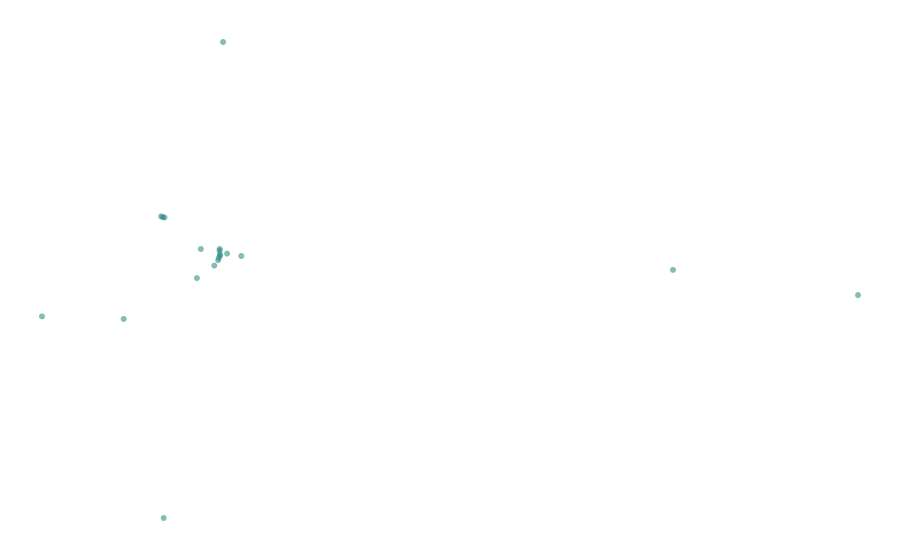

2026-11-03 00:26 INFO Rendered 20 profile coordinates for viruses


In [4]:
from html import escape
if len(plot_data):
    width, height, pad = 900, 560, 42
    x0, x1 = plot_data.x.min(), plot_data.x.max(); y0, y1 = plot_data.y.min(), plot_data.y.max()
    if x0 == x1: x1 = x0 + 1
    if y0 == y1: y1 = y0 + 1
    marks = []
    for row in plot_data.itertuples(index=False):
        x = pad + (row.x-x0)/(x1-x0)*(width-2*pad)
        y = height-pad-(row.y-y0)/(y1-y0)*(height-2*pad)
        title = escape(str(row.accepted_name))
        marks.append(f'<circle cx="{x:.1f}" cy="{y:.1f}" r="3" fill="#21857b" fill-opacity=".55"><title>{title}</title></circle>')
    svg = (f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">' f'<rect width="100%" height="100%" fill="white"/>{"".join(marks)}</svg>')
    from IPython.display import SVG, display
    display(SVG(svg))
else:
    svg = None
LOG.info('Rendered %d profile coordinates for %s', len(plot_data), GROUP_TO_PLOT)


## Step 4 · Record the plotted release and export

In [5]:
plot_record = {'source_payload': str(PAYLOAD_PATH.relative_to(ROOT)),
               'source_release': payload.get('schema_version'), 'group': GROUP_TO_PLOT,
               'host_id': HOST_ID_TO_PLOT, 'profiles_plotted': len(plot_data),
               'embedding': payload.get('embedding_runs', {}).get(HOST_ID_TO_PLOT),
               'run_id': payload.get('stats', {}).get('run_id')}
PLOT_DIR = ROOT / 'data/v4/plots'
PLOT_DIR.mkdir(parents=True, exist_ok=True)
if svg is not None:
    SVG_PATH = PLOT_DIR / f'{GROUP_TO_PLOT}-{HOST_ID_TO_PLOT.replace(":", "-")}-imste.svg'
    SVG_PATH.write_text(svg, encoding='utf-8')
    print('SVG saved:', SVG_PATH)
else:
    print('SVG export skipped because this host has no fitted coordinates.')
display(plot_record)
LOG.info('IMSTE coordinate inspection complete: %s', plot_record)


SVG saved: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/data/v4/plots/viruses-ncbi-4530-imste.svg


{'source_payload': 'sites/pathogen-atlas-explorer/explorer-data.json.gz',
 'source_release': 'v4-host-pathogen-atlas-v1',
 'group': 'viruses',
 'host_id': 'ncbi:4530',
 'profiles_plotted': 20,
 'embedding': {'embedding': 'IMSTE',
  'estimator': 'IteratedMinimumSpanningTreeEmbedder',
  'imste_version': '0.1.0',
  'host_id': 'ncbi:4530',
  'n_species': 20,
  'n_features': 12,
  'feature_ids': ['rice_stunting',
   'rice_increased_tillering',
   'rice_reduced_tillering',
   'rice_leaf_yellowing',
   'rice_leaf_striping_mosaic',
   'rice_leaf_distortion_galls',
   'rice_planthopper_vector',
   'rice_leafhopper_vector',
   'rice_whitefly_aphid_vector',
   'rice_soilborne_vector',
   'rice_beetle_vector',
   'rice_symptomatic_plant_association'],
  'input': 'curated literature feature-presence indicators; zero means not recorded and is used only for feature-space distance',
  'scaling': 'StandardScaler',
  'n_msts': 10,
  'n_epochs': 300,
  'mst_method': 'famst',
  'mst_neighbors': 15,
  'ran

2026-11-03 00:26 INFO IMSTE coordinate inspection complete: {'source_payload': 'sites/pathogen-atlas-explorer/explorer-data.json.gz', 'source_release': 'v4-host-pathogen-atlas-v1', 'group': 'viruses', 'host_id': 'ncbi:4530', 'profiles_plotted': 20, 'embedding': {'embedding': 'IMSTE', 'estimator': 'IteratedMinimumSpanningTreeEmbedder', 'imste_version': '0.1.0', 'host_id': 'ncbi:4530', 'n_species': 20, 'n_features': 12, 'feature_ids': ['rice_stunting', 'rice_increased_tillering', 'rice_reduced_tillering', 'rice_leaf_yellowing', 'rice_leaf_striping_mosaic', 'rice_leaf_distortion_galls', 'rice_planthopper_vector', 'rice_leafhopper_vector', 'rice_whitefly_aphid_vector', 'rice_soilborne_vector', 'rice_beetle_vector', 'rice_symptomatic_plant_association'], 'input': 'curated literature feature-presence indicators; zero means not recorded and is used only for feature-space distance', 'scaling': 'StandardScaler', 'n_msts': 10, 'n_epochs': 300, 'mst_method': 'famst', 'mst_neighbors': 15, 'random_

## Step 5 · Native embedding handoff

In [6]:
EMBEDDING_RUN = payload.get('embedding_runs', {}).get(HOST_ID_TO_PLOT)
EMBEDDING_RUN_READY = bool(EMBEDDING_RUN and EMBEDDING_RUN.get('embedding') == 'IMSTE' and len(plot_data) >= 2)
print('Rice IMSTE run ready:', EMBEDDING_RUN_READY)
print(json.dumps(EMBEDDING_RUN, indent=2, ensure_ascii=False))
if not EMBEDDING_RUN_READY:
    raise RuntimeError('Rice IMSTE coordinates are missing or incomplete; rebuild the Explorer data after fitting the rice feature profiles.')
LOG.info('Rice IMSTE fit and coordinate provenance inspected; profiles=%d', len(plot_data))


2026-11-03 00:26 INFO Rice IMSTE fit and coordinate provenance inspected; profiles=20


Rice IMSTE run ready: True
{
  "embedding": "IMSTE",
  "estimator": "IteratedMinimumSpanningTreeEmbedder",
  "imste_version": "0.1.0",
  "host_id": "ncbi:4530",
  "n_species": 20,
  "n_features": 12,
  "feature_ids": [
    "rice_stunting",
    "rice_increased_tillering",
    "rice_reduced_tillering",
    "rice_leaf_yellowing",
    "rice_leaf_striping_mosaic",
    "rice_leaf_distortion_galls",
    "rice_planthopper_vector",
    "rice_leafhopper_vector",
    "rice_whitefly_aphid_vector",
    "rice_soilborne_vector",
    "rice_beetle_vector",
    "rice_symptomatic_plant_association"
  ],
  "input": "curated literature feature-presence indicators; zero means not recorded and is used only for feature-space distance",
  "scaling": "StandardScaler",
  "n_msts": 10,
  "n_epochs": 300,
  "mst_method": "famst",
  "mst_neighbors": 15,
  "random_state": 42,
  "device": "cpu",
  "coordinate_std": [
    0.42602697014808655,
    0.43918877840042114
  ],
  "coordinate_range": [
    [
      -0.48730331